# Exercises XP Gold — K-means from scratch

In this exercise, I write my own K-means clustering in NumPy and use it to split the points of `ex7data2.mat` into groups. I follow the course's pre-filled Colab notebook and complete its TODO parts.

### What I learn here
- Euclidean distance and assigning each point to its closest centroid.
- How the centroid updates make each cluster tighter.
- Why the random starting centroids matter and how I compare different runs.

## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. I keep `ex7data2.zip` in my `C:\Users\sivan\Datasets` folder. It holds the course file [ex7data2.mat](https://github.com/krasserm/machine-learning-notebooks/blob/master/data/ml-ex7/ex7data2.mat).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `ex7data2.zip`.

In [ ]:
from google.colab import files
# I import Colab's tool for uploading files from my computer.
uploaded = files.upload()
# I open a file picker and choose "ex7data2.zip".
!unzip "ex7data2.zip"
# I extract ex7data2.mat from the zip into Colab.

## Task 1 - Load and visualize the dataset

In this task, I load `ex7data2.mat` with `scipy.io.loadmat`, check its shape and first rows, and draw the points in a scatter plot.

### What I learn here
- I read a MATLAB file into a NumPy array.
- I look at unlabeled data before clustering it.

Shape of X: (300, 2)
[[1.84207953 4.6075716 ]
 [5.65858312 4.79996405]
 [6.35257892 3.2908545 ]
 [2.90401653 4.61220411]
 [3.23197916 4.93989405]]


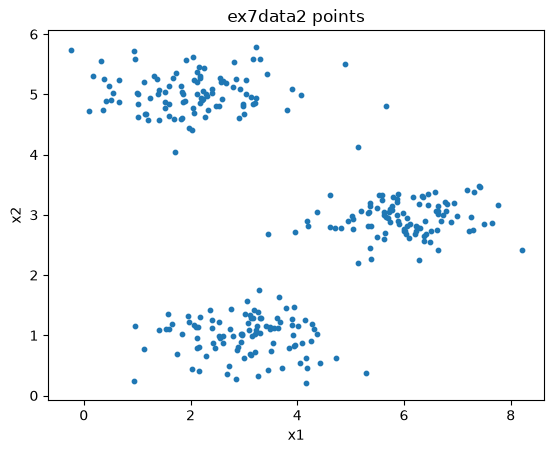

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

mat_path = 'ex7data2.mat'
# loadmat returns a dictionary. The points are stored under the key 'X'.
data = loadmat(mat_path)
X = data['X']
# m rows (points) and 2 columns (coordinates)
print('Shape of X:', X.shape)
print(X[:5])

plt.figure()
plt.scatter(X[:, 0], X[:, 1], s=10)
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('ex7data2 points')
plt.show()

## Task 2 - Finding closest centroids

In this task, I write `find_closest_centroids` that gives each point the index of its closest centroid, using Euclidean distance. I test it with the starting centroids `[[3, 3], [6, 2], [8, 5]]` and print the closest centroid of the first three points.

### What I learn here
- I measure Euclidean distance between a point and a centroid.
- I use `np.argmin` to pick the closest centroid.

In [2]:
def find_closest_centroids(X, centroids):
    """Return idx of shape (m,) with index of closest centroid for each point."""
    m = X.shape[0]
    K = centroids.shape[0]
    # One row per point, one column per centroid.
    distances = np.zeros((m, K))
    for k in range(K):
        # Squared Euclidean distance from every point to centroid k.
        distances[:, k] = np.sum((X - centroids[k]) ** 2, axis=1)
        # The real distance is np.sqrt(...) of this. I skip the square root
        # because it does not change which centroid is the closest.
    # For each row (point), the column with the smallest distance is its cluster.
    idx = np.argmin(distances, axis=1)
    return idx

# Test
init_centroids = np.array([[3,3],[6,2],[8,5]], dtype=float)
idx = find_closest_centroids(X, init_centroids)
print(idx[:3])

[0 2 1]


**My result:** The printed indices are `[0 2 1]`: the first point is closest to centroid 0 `[3, 3]`, the second to centroid 2 `[8, 5]`, and the third to centroid 1 `[6, 2]`. This matches the expected result of the original exercise (1, 3, 2 when counting from 1).

## Task 3 - Computing centroids

In this task, I write `compute_centroids` that moves each centroid to the mean of the points assigned to it. If a cluster has no points, I give it a random point from `X`, as the template says. I test it by printing the new centroids.

### What I learn here
- I compute the mean of the points in each cluster.

In [3]:
def compute_centroids(X, idx, K, rng=None):
    m, n = X.shape
    new_centroids = np.zeros((K, n), dtype=float)
    # rng is NumPy's random number generator (the template's way of choosing random values).
    rng = np.random.default_rng() if rng is None else rng
    for k in range(K):
        # I keep only the points assigned to cluster k.
        pts = X[idx == k]
        if pts.shape[0] == 0:
            # Empty cluster: I restart it at one random point of X.
            new_centroids[k] = X[rng.integers(0, m)]
        else:
            # The mean of each coordinate (column) of the cluster's points.
            new_centroids[k] = pts.mean(axis=0)
            # By hand: pts.sum(axis=0) / len(pts)
    return new_centroids

# Example test
idx_test = find_closest_centroids(X, init_centroids)
print(compute_centroids(X, idx_test, K=3))

[[2.42830111 3.15792418]
 [5.81350331 2.63365645]
 [7.11938687 3.6166844 ]]


## Task 4 - Running K-means

In this task, I write `run_k_means`, which repeats "assign points, then update centroids" for `max_iters` iterations and keeps a history of the centroids. I run it for 10 iterations, plot the clusters in different colors with the final centroids, and show how the centroids move (converge).

### What I learn here
- I see how K-means repeats two simple steps.
- I see the centroids move and then stop changing.

Final centroids:
[[1.95399466 5.02557006]
 [3.04367119 1.01541041]
 [6.03366736 3.00052511]]


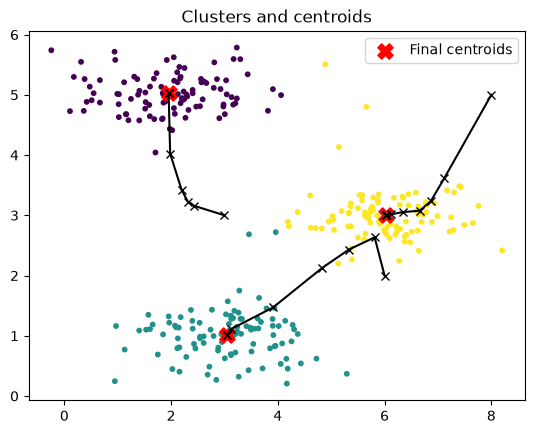

In [4]:
def run_k_means(X, init_centroids, max_iters=10, rng=None):
    K = init_centroids.shape[0]
    centroids = init_centroids.copy().astype(float)
    # I save the centroids after every iteration so I can plot their path.
    history = [centroids.copy()]
    idx = None
    for it in range(max_iters):
        # Step 1: assign every point to its closest centroid.
        idx = find_closest_centroids(X, centroids)
        # Step 2: move each centroid to the mean of its points.
        centroids = compute_centroids(X, idx, K, rng=rng)
        history.append(centroids.copy())
    return centroids, idx, history

# Example run
final_centroids, idx, hist = run_k_means(X, init_centroids, max_iters=10)
print('Final centroids:')
print(final_centroids)

plt.figure()
# I color each point by its cluster index.
plt.scatter(X[:,0], X[:,1], c=idx, s=10)
# I turn the history list into an array of shape (11, 3, 2): iterations, centroids, coordinates.
hist_array = np.array(hist)
for k in range(3):
    # The path of centroid k over the iterations (x marks every step).
    plt.plot(hist_array[:, k, 0], hist_array[:, k, 1], 'kx-')
plt.scatter(final_centroids[:,0], final_centroids[:,1], marker='X', s=120, c='red', label='Final centroids')
plt.legend()
plt.title('Clusters and centroids'); plt.show()

**My result:** After 10 iterations, the printed final centroids are about `[1.95, 5.03]`, `[3.04, 1.02]` and `[6.03, 3.00]`. In the plot, the three colors form three clear groups, and the black paths show each centroid moving from its starting point toward the middle of its group. The steps get shorter at the end, which means the centroids have converged.

## Task 5 - Initializing centroids

In this task, I write `init_centroids`, which picks K different random points from `X` as starting centroids. I test it for 3 clusters and print them.

### What I learn here
- I choose random rows without picking the same row twice.

In [5]:
def init_centroids(X, K, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    m = X.shape[0]
    # I choose K different row numbers. replace=False means no row is chosen twice.
    idx = rng.choice(m, size=K, replace=False)
    # I return those rows as the starting centroids.
    return X[idx].astype(float)

# I give the generator a seed (0) so I get the same random centroids every time I run it.
print(init_centroids(X, 3, np.random.default_rng(0)))

[[2.94294356 1.02825076]
 [2.95818429 1.01887096]
 [6.92721968 3.19960026]]


## Task 6 - Multiple initializations and evaluation

In this task, I run K-means with several random starts and compare them with the inertia, the sum of squared distances from each point to its centroid (`withinss`). I keep the run with the lowest inertia and save a report with the cluster of each point.

### What I learn here
- I see that different starting centroids can give different results.
- I use the inertia to choose the best run (lower means tighter clusters).

In [6]:
import pandas as pd

def withinss(X, centroids, idx):
    # centroids[idx] gives every point its own centroid, so I can subtract row by row.
    diffs = X - centroids[idx]
    # I square the differences and add them all up.
    return float(np.sum(diffs * diffs))

best = {'score': np.inf}
for seed in range(5):
    # A different seed gives different random starting centroids.
    rng = np.random.default_rng(seed)
    c0 = init_centroids(X, 3, rng)
    cF, idxF, hist = run_k_means(X, c0, max_iters=10, rng=rng)
    s = withinss(X, cF, idxF)
    print('Seed', seed, 'inertia:', round(s, 2))
    # I keep this run if its inertia is the lowest so far.
    if s < best['score']:
        best = {'score': s, 'centroids': cF, 'idx': idxF, 'seed': seed}
print('Best seed:', best['seed'], '| Best inertia:', round(best['score'], 2))

# My report: the coordinates of each point and its cluster label.
rep = pd.DataFrame({'x1': X[:,0], 'x2': X[:,1], 'cluster': best['idx']})
rep.to_csv('kmeans_assignments.csv', index=False)
print('Wrote kmeans_assignments.csv')
display(rep.head())
# I count how many points ended up in each cluster.
print(rep['cluster'].value_counts().sort_index())

Seed 0 inertia: 266.66
Seed 1 inertia: 266.66
Seed 2 inertia: 266.66
Seed 3 inertia: 858.41
Seed 4 inertia: 266.66
Best seed: 0 | Best inertia: 266.66
Wrote kmeans_assignments.csv


,x1,x2,cluster
0,1.842080,4.607572,0
1,5.658583,4.799964,2
2,6.352579,3.290854,2
3,2.904017,4.612204,0
4,3.231979,4.939894,0


cluster
0     98
1    102
2    100
Name: count, dtype: int64


**My result:** From the printed inertias, seeds 0, 1, 2 and 4 all reach the same inertia of **266.66**, but seed 3 gets stuck at **858.41**, a much worse result. So a bad random start can give wrong clusters, and running several starts and keeping the lowest inertia protects me from that. My Task 5 test shows such a bad start: two of the three random centroids, `[2.94, 1.03]` and `[2.96, 1.02]`, are almost the same point. In the best run (seed 0), the report gives 98, 102 and 100 points to clusters 0, 1 and 2.